In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("C:/Users/LENOVO/Downloads/Synthetic (1).csv")

In [6]:
df.head()

,Unnamed: 0,X,Y
0,0,37.454012,126.746701
1,1,95.071431,293.927975
2,2,73.199394,225.441700
3,3,59.865848,183.586508
4,4,15.601864,39.020372


In [7]:
df.drop(columns=["Unnamed: 0"], inplace=True)

In [8]:
df.head()

,X,Y
0,37.454012,126.746701
1,95.071431,293.927975
2,73.199394,225.441700
3,59.865848,183.586508
4,15.601864,39.020372


In [9]:
# Extract features and labels
x = df.iloc[:, 0].values
y = df.iloc[:, 1].values

In [10]:
x.shape, y.shape

((50,), (50,))

In [11]:
x = (x - np.mean(x)) / np.std(x)

In [12]:
x = x.reshape(1, -1)
y = y.reshape(-1, 1)

In [13]:
x.shape, y.shape

((1, 50), (50, 1))

In [14]:
noOfFeatures, m = x.shape

In [15]:
# Initialize model parameters
theta_0 = np.array(np.random.randn()).reshape(1,1)
theta_1 = np.array(np.random.randn()).reshape(1,1)

In [16]:
theta_0.shape, theta_1.shape

((1, 1), (1, 1))

In [17]:
learning_rate = 0.0001
epochs = 10000
tolerance = 0.001

In [18]:
epoch = 1
loss = 1
losses = []

while epoch <= epochs and loss > tolerance:

    # Forward pass
    y_hat = theta_0 * x + theta_1

    # Loss calculation
    loss = 1/2 * np.mean((y_hat.T - y)**2)

    # derivative calculation
    d_theta_0 = 1/m * np.dot(x, (y_hat.T - y))
    d_theta_1 = 1/m * np.sum(y_hat.T - y)

    # Update parameters
    theta_0 = theta_0 - learning_rate * d_theta_0
    theta_1 = theta_1 - learning_rate * d_theta_1

    losses.append(loss)

    epoch += 1

In [19]:
print(theta_0.shape, theta_1.shape)

(1, 1) (1, 1)


In [20]:
print(type(losses))

<class 'list'>


Text(0, 0.5, 'Loss (MSE)')

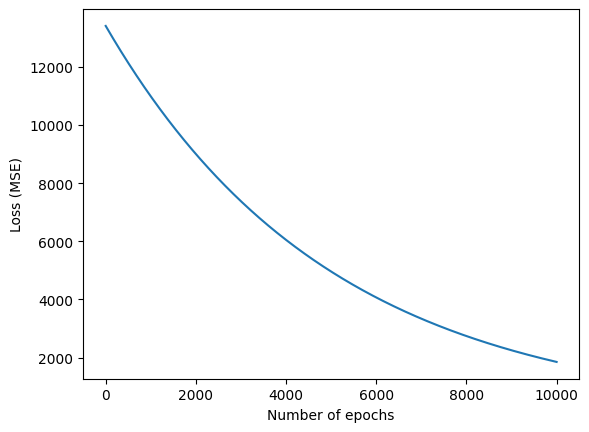

In [21]:
plt.plot(losses)
plt.xlabel("Number of epochs")
plt.ylabel("Loss (MSE)")

## Stochastic Gradient Descent (SGD)

The loop above is **batch** vanilla gradient descent: one parameter update per epoch, using the gradient over all `m` examples.

In **SGD** we update the parameters after *every single example*, so one epoch = `m` updates. We shuffle the data at the start of each epoch so the updates don't follow a fixed order.

In [22]:
# Re-initialize parameters for SGD (fresh start, same shapes as before)
theta_0_sgd = np.array(np.random.randn()).reshape(1,1)
theta_1_sgd = np.array(np.random.randn()).reshape(1,1)

learning_rate_sgd = 0.0001
epochs_sgd = 10000
tolerance_sgd = 0.001


In [23]:
epoch = 1
loss = 1
losses_sgd = []

while epoch <= epochs_sgd and loss > tolerance_sgd:

    # Shuffle the examples every epoch
    indices = np.random.permutation(m)

    for i in indices:
        x_i = x[:, i:i+1]      # shape (1, 1)
        y_i = y[i:i+1, :]      # shape (1, 1)

        # Forward pass on ONE example
        y_hat_i = theta_0_sgd * x_i + theta_1_sgd

        # Gradient from ONE example (no 1/m, since there is only one sample)
        d_theta_0 = x_i * (y_hat_i - y_i)
        d_theta_1 = (y_hat_i - y_i)

        # Update parameters immediately
        theta_0_sgd = theta_0_sgd - learning_rate_sgd * d_theta_0
        theta_1_sgd = theta_1_sgd - learning_rate_sgd * d_theta_1

    # Loss on the full data at the end of the epoch (for comparison with batch GD)
    y_hat = theta_0_sgd * x + theta_1_sgd
    loss = 1/2 * np.mean((y_hat.T - y)**2)
    losses_sgd.append(loss)

    epoch += 1


In [24]:
print("Batch GD  -> slope:", theta_0.item(), " intercept:", theta_1.item(), " epochs run:", len(losses))
print("SGD       -> slope:", theta_0_sgd.item(), " intercept:", theta_1_sgd.item(), " epochs run:", len(losses_sgd))


Batch GD  -> slope: 54.081661422578605  intercept: 89.23709543160997  epochs run: 10000
SGD       -> slope: 85.15492447115643  intercept: 140.7477549711662  epochs run: 10000


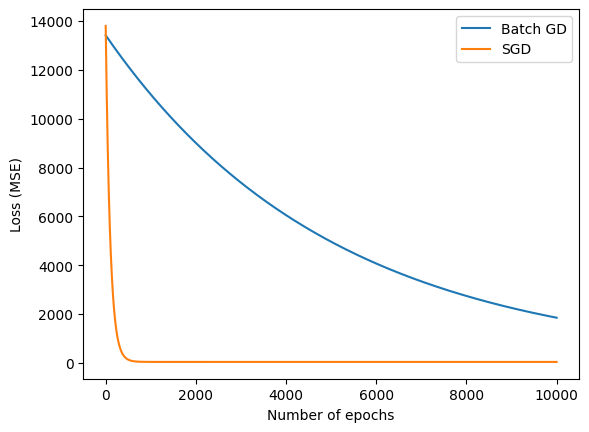

In [25]:
plt.plot(losses, label="Batch GD")
plt.plot(losses_sgd, label="SGD")
plt.xlabel("Number of epochs")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()


**Observation:** per epoch, SGD makes `m` updates versus 1 for batch GD, so it usually reduces the loss much faster in terms of epochs. Its path is noisier because each step uses a single example, but it settles near the same line as batch GD.